<a href="https://colab.research.google.com/github/ainunjry/Tools_Project-2_Delivery-Analysis/blob/main/Delivery.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

In [ ]:
!pip install pandas
!pip install matplotlib

In [ ]:
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
import numpy as np

In [ ]:
# Creating variable to read the dataset
dv = pd.read_excel('RESTAURANT.xlsx')

In [ ]:
# Transforming the dataset into DataFrame
dv = pd.DataFrame(dv)
print(type(dv))

<class 'pandas.core.frame.DataFrame'>


In [ ]:
# To display the first-5-row of DataFrame
dv.head()

,order_id,customer_id,restaurant_id,driver_id,order_timestamp,order_date,order_hour,day_of_week,is_weekend,city,...,traffic_level,delivery_partner_experience_months,delivery_partner_rating,restaurant_preparation_time_minutes,estimated_delivery_time_minutes,actual_delivery_time_minutes,late_delivery,order_status,cancellation_reason,customer_rating
0,ORD_000001,CUS_00001,RES_0008,DRV_0075,2025-10-05 15:54:00,2025-10-05,15,Sunday,1,City_C,...,Medium,14,4.4,25,25,29.0,0.0,Completed,NaN,4.6
1,ORD_000002,CUS_00013,RES_0024,DRV_0131,2025-10-01 20:00:00,2025-10-01,20,Wednesday,0,City_A,...,High,44,4.7,12,20,24.0,0.0,Completed,NaN,5.0
2,ORD_000003,CUS_00049,RES_0013,DRV_0087,2025-10-07 18:24:00,2025-10-07,18,Tuesday,0,City_C,...,High,1,5.0,11,63,72.0,1.0,Completed,NaN,3.6
3,ORD_000004,CUS_00007,RES_0001,DRV_0177,2025-10-30 16:54:00,2025-10-30,16,Thursday,0,City_A,...,Low,50,4.3,12,23,31.0,1.0,Completed,NaN,4.1
4,ORD_000005,CUS_00325,RES_0029,DRV_0114,2025-10-15 18:34:00,2025-10-15,18,Wednesday,0,City_B,...,Medium,21,4.0,9,32,42.0,1.0,Completed,NaN,3.9


In [ ]:
# To identify the number of rows and  datatype for each column
dv.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 50000 entries, 0 to 49999
Data columns (total 37 columns):
 #   Column                               Non-Null Count  Dtype         
---  ------                               --------------  -----         
 0   order_id                             50000 non-null  object        
 1   customer_id                          50000 non-null  object        
 2   restaurant_id                        50000 non-null  object        
 3   driver_id                            50000 non-null  object        
 4   order_timestamp                      50000 non-null  datetime64[ns]
 5   order_date                           50000 non-null  datetime64[ns]
 6   order_hour                           50000 non-null  int64         
 7   day_of_week                          50000 non-null  object        
 8   is_weekend                           50000 non-null  int64         
 9   city                                 50000 non-null  object        
 10  delivery_a

In [ ]:
dv.shape

(50000, 37)

In [ ]:
# To identify the dataset statistic
dv.describe(include='all')

,order_id,customer_id,restaurant_id,driver_id,order_timestamp,order_date,order_hour,day_of_week,is_weekend,city,...,traffic_level,delivery_partner_experience_months,delivery_partner_rating,restaurant_preparation_time_minutes,estimated_delivery_time_minutes,actual_delivery_time_minutes,late_delivery,order_status,cancellation_reason,customer_rating
count,50000,50000,50000,50000,50000,50000,50000.000000,50000,50000.00000,50000,...,50000,50000.0000,50000.000000,50000.000000,50000.000000,49132.000000,49132.000000,50000,868,49132.000000
unique,50000,4979,250,200,NaN,NaN,NaN,7,NaN,4,...,3,NaN,NaN,NaN,NaN,NaN,NaN,2,5,NaN
top,ORD_000001,CUS_00001,RES_0001,DRV_0066,NaN,NaN,NaN,Thursday,NaN,City_A,...,Medium,NaN,NaN,NaN,NaN,NaN,NaN,Completed,Driver Unassigned,NaN
freq,1,4510,8837,315,NaN,NaN,NaN,8472,NaN,19888,...,19522,NaN,NaN,NaN,NaN,NaN,NaN,49132,386,NaN
mean,NaN,NaN,NaN,NaN,2025-10-16 04:28:15.081600,2025-10-15 13:30:58.752000256,14.465900,NaN,0.26712,NaN,...,NaN,29.7332,4.495062,15.549600,30.950580,35.152365,0.365709,NaN,NaN,4.295946
min,NaN,NaN,NaN,NaN,2025-10-01 00:00:00,2025-10-01 00:00:00,0.000000,NaN,0.00000,NaN,...,NaN,1.0000,3.200000,5.000000,8.000000,10.000000,0.000000,NaN,NaN,1.800000
25%,NaN,NaN,NaN,NaN,2025-10-08 15:00:30,2025-10-08 00:00:00,11.000000,NaN,0.00000,NaN,...,NaN,14.0000,4.300000,10.000000,22.000000,25.000000,0.000000,NaN,NaN,4.000000
50%,NaN,NaN,NaN,NaN,2025-10-16 09:24:00,2025-10-16 00:00:00,14.000000,NaN,0.00000,NaN,...,NaN,29.0000,4.500000,14.000000,28.000000,33.000000,0.000000,NaN,NaN,4.400000
75%,NaN,NaN,NaN,NaN,2025-10-23 16:52:15,2025-10-23 00:00:00,19.000000,NaN,1.00000,NaN,...,NaN,44.0000,4.800000,19.000000,37.000000,42.000000,1.000000,NaN,NaN,4.700000
max,NaN,NaN,NaN,NaN,2025-10-30 23:59:00,2025-10-30 00:00:00,23.000000,NaN,1.00000,NaN,...,NaN,60.0000,5.000000,73.000000,128.000000,172.000000,1.000000,NaN,NaN,5.000000


In [ ]:
# To check the duplicates
dv.duplicated().sum()

np.int64(0)

In [ ]:
# Creating function to identify missing values
def missing (a,b):
  hasil = a[b].isnull().sum()
  print(f'The number of missing values column {b} : {hasil}')


In [ ]:
  missing(dv,'tip_amount')
  missing(dv,'subtotal')
  missing(dv,'actual_delivery_time_minutes')
  missing(dv,'late_delivery')
  missing(dv,'customer_rating')
  missing(dv,'restaurant_rating')

The number of missing values column tip_amount : 868
The number of missing values column subtotal : 0
The number of missing values column actual_delivery_time_minutes : 868
The number of missing values column late_delivery : 868
The number of missing values column customer_rating : 868
The number of missing values column restaurant_rating : 0


In [ ]:
# Creating DataFrame copy
dv1 = dv.copy()

In [ ]:
dv1.head(3)

,order_id,customer_id,restaurant_id,driver_id,order_timestamp,order_date,order_hour,day_of_week,is_weekend,city,...,traffic_level,delivery_partner_experience_months,delivery_partner_rating,restaurant_preparation_time_minutes,estimated_delivery_time_minutes,actual_delivery_time_minutes,late_delivery,order_status,cancellation_reason,customer_rating
0,ORD_000001,CUS_00001,RES_0008,DRV_0075,2025-10-05 15:54:00,2025-10-05,15,Sunday,1,City_C,...,Medium,14,4.4,25,25,29.0,0.0,Completed,NaN,4.6
1,ORD_000002,CUS_00013,RES_0024,DRV_0131,2025-10-01 20:00:00,2025-10-01,20,Wednesday,0,City_A,...,High,44,4.7,12,20,24.0,0.0,Completed,NaN,5.0
2,ORD_000003,CUS_00049,RES_0013,DRV_0087,2025-10-07 18:24:00,2025-10-07,18,Tuesday,0,City_C,...,High,1,5.0,11,63,72.0,1.0,Completed,NaN,3.6


In [ ]:
# Identifying minimum value column 'tip_amount'
dv1['tip_amount'].min()

0.0

In [ ]:
# Identifying the number of rows that contain NOT min_value
(dv1['tip_amount'] != 0.0).sum()

np.int64(21711)

In [ ]:
# Identifying the number of rows that contain min_value
(dv1['tip_amount'] == 0.0).sum()

np.int64(28289)

In [ ]:
# Replacing missing values
# column tip_amount
dv1['tip_amount'].replace(np.nan , dv1['tip_amount'].min(), inplace = True)

/tmp/ipykernel_2469/4286448334.py:3: FutureWarning: A value is trying to be set on a copy of a DataFrame or Series through chained assignment using an inplace method.
The behavior will change in pandas 3.0. This inplace method will never work because the intermediate object on which we are setting values always behaves as a copy.

For example, when doing 'df[col].method(value, inplace=True)', try using 'df.method({col: value}, inplace=True)' or df[col] = df[col].method(value) instead, to perform the operation inplace on the original object.


  dv1['tip_amount'].replace(np.nan , dv1['tip_amount'].min(), inplace = True)


In [ ]:
# The total rows after replacing are 28289 + 868 (missing value)
(dv1['tip_amount'] == 0.0).sum()

np.int64(29157)

In [ ]:
# Identifying the number of rows that contain > 0 value
(dv1['actual_delivery_time_minutes'] > 0).sum()

np.int64(49132)

In [ ]:
# Replacing missing values column actual_delivery_time_minutes
dv1['actual_delivery_time_minutes']=dv1['actual_delivery_time_minutes'].fillna(0.0)

In [ ]:
dv1['actual_delivery_time_minutes'].isnull().sum()

np.int64(0)

In [ ]:
(dv1['actual_delivery_time_minutes'] == 0.0).sum()

np.int64(868)

In [ ]:
# column late_delivery

dv1['late_delivery'] = dv1['late_delivery'].fillna('Cancelled order')

In [ ]:
dv1['late_delivery'].isnull().sum()

np.int64(0)

In [ ]:
(dv1['late_delivery'] == 'Cancelled order') .sum()

np.int64(868)

In [ ]:
# column customer_rating
dv1['customer_rating'] = dv1['customer_rating'].fillna(0.0)

In [ ]:
dv1['customer_rating'].isnull().sum()

np.int64(0)

In [ ]:
(dv1['customer_rating'] == 0.0).sum()

np.int64(868)

In [ ]:
def rows (a,b):
  numbers = (a[b] == 0).sum()
  print(f'the number of rows column {b} = 0 are : {numbers}')

rows (dv1,'tip_amount')
rows (dv1,'actual_delivery_time_minutes')
rows (dv1,'late_delivery')
rows (dv1,'customer_rating')

the number of rows column tip_amount = 0 are : 29157
the number of rows column actual_delivery_time_minutes = 0 are : 868
the number of rows column late_delivery = 0 are : 31164
the number of rows column customer_rating = 0 are : 868


In [ ]:
''' The missing values of column:
'tip_amount': replaced by minimum value of column 0.0.
'actual_delivery_time_minutes' : replaced by 0.0, due to cancelled order status.
'late_delivery : replaced by " Undefined " due to cancelled order status.
'customer_rating' : replaced by 0.0 due to cancelled order status.
'''

In [ ]:
dv1.drop(columns= 'order_timestamp', inplace=True)

In [ ]:
# Transforming datetime column order_date into Y-m-d
dv1['new_order_date'] = pd.to_datetime(dv1['order_date']).dt.strftime('%Y-%m-%d')

In [ ]:
dv1.head(3)

,order_id,customer_id,restaurant_id,driver_id,order_date,order_hour,day_of_week,is_weekend,city,delivery_area,...,delivery_partner_experience_months,delivery_partner_rating,restaurant_preparation_time_minutes,estimated_delivery_time_minutes,actual_delivery_time_minutes,late_delivery,order_status,cancellation_reason,customer_rating,new_order_date
0,ORD_000001,CUS_00001,RES_0008,DRV_0075,2025-10-05,15,Sunday,1,City_C,City_C_Area_3,...,14,4.4,25,25,29.0,0.0,Completed,NaN,4.6,2025-10-05
1,ORD_000002,CUS_00013,RES_0024,DRV_0131,2025-10-01,20,Wednesday,0,City_A,City_A_Area_1,...,44,4.7,12,20,24.0,0.0,Completed,NaN,5.0,2025-10-01
2,ORD_000003,CUS_00049,RES_0013,DRV_0087,2025-10-07,18,Tuesday,0,City_C,City_C_Area_3,...,1,5.0,11,63,72.0,1.0,Completed,NaN,3.6,2025-10-07


In [ ]:
print(dv1['new_order_date'].dtype)

object


In [ ]:
#Transforming the data type column 'new_order_date' into datetime
dv1['new_order_date'] = pd.to_datetime(dv1['new_order_date'])

In [ ]:
print(dv1['new_order_date'].dtype)

datetime64[ns]


In [ ]:
#Transforming the data type column 'new_order_date' into period
dv1['new_order_date'] = dv1['new_order_date'].dt.to_period('D')
# Transforming into period 'll work out , should the column dv1['new_order_date'] had been changed into datetime first place.

In [ ]:
# Transformimg column 'actual_delivery_time_minutes' into interger
dv1['actual_delivery_time_minutes'] = dv1['actual_delivery_time_minutes'].astype('int64')

In [ ]:
dv1.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 50000 entries, 0 to 49999
Data columns (total 37 columns):
 #   Column                               Non-Null Count  Dtype         
---  ------                               --------------  -----         
 0   order_id                             50000 non-null  object        
 1   customer_id                          50000 non-null  object        
 2   restaurant_id                        50000 non-null  object        
 3   driver_id                            50000 non-null  object        
 4   order_date                           50000 non-null  datetime64[ns]
 5   order_hour                           50000 non-null  int64         
 6   day_of_week                          50000 non-null  object        
 7   is_weekend                           50000 non-null  int64         
 8   city                                 50000 non-null  object        
 9   delivery_area                        50000 non-null  object        
 10  customer_a

In [ ]:
# EXPLORATORY DATA ANALYSIS
# Identifying distribution of column : customer_age, distance_km, actual_delivery_time_minutes

In [ ]:
# Creating function to identify: mean, median, skewness and histogram distribution.

def statistic (a,b):
  mean = np.round(a[b].mean(),2)
  median = np.round(a[b].median(),2)
  skewness = a[b].skew()

  print(f"the mean of  {b} column : {mean}")
  print(f"the median of {b} column: {median}")
  print(f"the skewness of{b} column : {skewness}")

In [ ]:
statistic(dv1,'customer_age')

the mean of  customer_age column : 27.69
the median of customer_age column: 27.0
the skewness ofcustomer_age column : 0.509064156984098


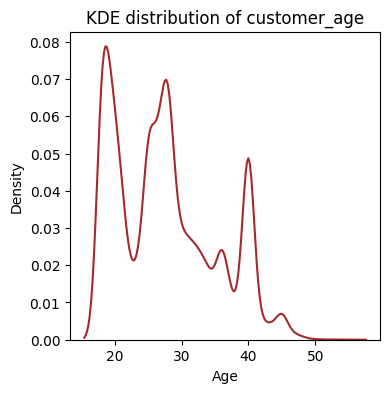

In [ ]:
plt.figure(figsize = (4,4))
sns.kdeplot(data=dv1, x='customer_age', fill=False, color='brown')
plt.title("KDE distribution of customer_age")
plt.xlabel("Age")
plt.show()

In [ ]:
''' The 3 peaks indicates 3 subs-population in dataset, that range
    18 - 28 years, 29 - 39 years, and over 40 years.
    the median and mean were similar, the gen Z population contributed
    the most delivery-order-customers.'''

In [ ]:
statistic(dv1,'distance_km')

the mean of  distance_km column : 4.73
the median of distance_km column: 4.1
the skewness ofdistance_km column : 1.7050089288964454


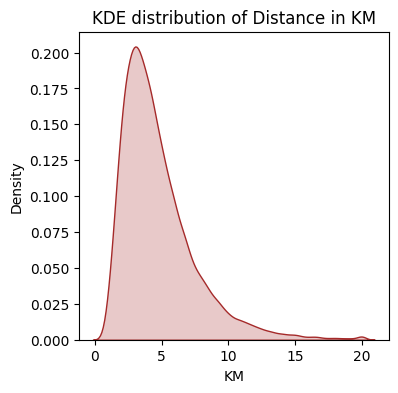

In [ ]:
plt.figure(figsize=(4,4))
sns.kdeplot(data=dv1, x='distance_km', fill=True, color='brown')
plt.title('KDE distribution of Distance in KM')
plt.xlabel('KM')
plt.show()

In [ ]:
'''The distance distribution is strongly right skewed,
   It has small number of high values to pull the Mean upward.
   Furthermore,  the Median provides  a more representative view of a typical distance_km.'''

In [ ]:
statistic(dv1, 'actual_delivery_time_minutes')

the mean of  actual_delivery_time_minutes column : 34.54
the median of actual_delivery_time_minutes column: 32.0
the skewness ofactual_delivery_time_minutes column : 1.1576023425072235


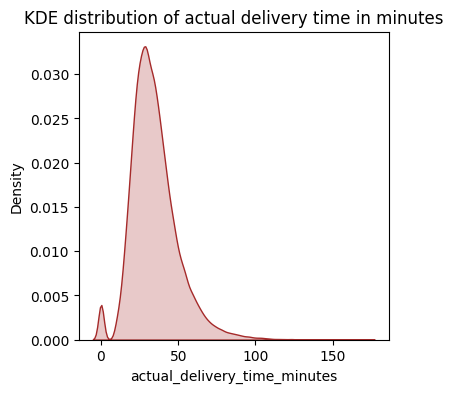

In [ ]:
plt.figure(figsize=(4,4))
sns.kdeplot(data=dv1, x='actual_delivery_time_minutes', fill=True, color='brown')
plt.title('KDE distribution of actual delivery time in minutes')
plt.xlabel('actual_delivery_time_minutes')
plt.show()

In [ ]:
'''The Mean  of actual delivery time( 34.54 ) is higher than the Median
(32.0), largely a small group of  substantially high-minutes of actual time delivery,
therefore the small group of substantially high-minutes pull the Mean upward,
hence It's strongly right skewed.'''

In [ ]:
Q1 = dv1['distance_km'].quantile(0.25)
Q3 = dv1['distance_km'].quantile(0.75)
IQR = Q3 - Q1
Lower = Q1 - (1.5*Q1)
Upper = Q3 + (1.5*Q3)
Outliers = dv1['distance_km'][(dv1['distance_km'] < Lower) | (dv1['distance_km'] > Upper)]
No_Outliers = dv1['distance_km'][(dv1['distance_km'] >= Lower) & (dv1['distance_km'] <= Upper)]

print(f'Q1 = {Q1}')
print(f'Q3 = {Q3}')
print(f'IQR = {IQR}')
print(f'Lower = {Lower}')
print(f'Upper = {Upper}')
print(f'Outliers = {Outliers}')
print(f'No Outliers = {No_Outliers}')
print(f'The number of outliers : {len(Outliers)}')
print(f'The number od No Outliers : {len(No_Outliers)}')


Q1 = 2.8
Q3 = 5.9
IQR = 3.1000000000000005
Lower = -1.3999999999999995
Upper = 14.750000000000002
Outliers = 188      20.0
228      17.2
500      17.6
594      16.7
633      16.3
         ... 
49572    17.1
49681    17.1
49816    20.0
49941    16.2
49980    16.1
Name: distance_km, Length: 509, dtype: float64
No Outliers = 0         1.1
1         2.5
2        11.8
3         5.4
4         6.1
         ... 
49995     2.9
49996     3.8
49997     2.1
49998     1.5
49999     7.3
Name: distance_km, Length: 49491, dtype: float64
The number of outliers : 509
The number od No Outliers : 49491


In [ ]:
# Identifying outliers
# Creating function

def otl(c,d):
  Q1 = c[d].quantile(0.25)
  Q3 = c[d].quantile(0.75)
  IQR = Q3 - Q1
  Lower = Q1 - (1.5*Q1)
  Upper = Q3 + (1.5*Q3)

  Outliers = c[d][(c[d] < Lower) | (c[d] > Upper)]
  No_Outliers = c[d][(c[d] >= Lower) & (c[d] <= Upper)]

  print(f'Q1 = {Q1}')
  print(f'Q3 = {Q3}')
  print(f'IQR = {IQR}')
  print(f'Lower = {Lower}')
  print(f'Upper = {Upper}')
  if Outliers.empty:
    print(f'{d} Column has no Outliers')
  else:
    print(f'The number of outliers of {d}: {len(Outliers)}')


In [ ]:
  otl(dv1,'distance_km')

Q1 = 2.8
Q3 = 5.9
IQR = 3.1000000000000005
Lower = -1.3999999999999995
Upper = 14.750000000000002
The number of outliers of distance_km: 509


In [ ]:
dv1[dv1['distance_km'] > 14.75]

,order_id,customer_id,restaurant_id,driver_id,order_date,order_hour,day_of_week,is_weekend,city,delivery_area,...,delivery_partner_experience_months,delivery_partner_rating,restaurant_preparation_time_minutes,estimated_delivery_time_minutes,actual_delivery_time_minutes,late_delivery,order_status,cancellation_reason,customer_rating,new_order_date
188,ORD_000189,CUS_00002,RES_0003,DRV_0067,2025-10-08,10,Wednesday,0,City_C,City_C_Area_5,...,1,4.6,6,79,76,0.0,Completed,NaN,4.4,2025-10-08
228,ORD_000229,CUS_00002,RES_0003,DRV_0176,2025-10-20,14,Monday,0,City_C,City_C_Area_1,...,12,3.8,14,89,96,1.0,Completed,NaN,3.9,2025-10-20
500,ORD_000501,CUS_03855,RES_0088,DRV_0166,2025-10-07,19,Tuesday,0,City_B,City_B_Area_1,...,7,4.2,15,91,104,1.0,Completed,NaN,3.8,2025-10-07
594,ORD_000595,CUS_00005,RES_0004,DRV_0036,2025-10-13,13,Monday,0,City_B,City_B_Area_5,...,49,5.0,16,73,84,1.0,Completed,NaN,4.1,2025-10-13
633,ORD_000634,CUS_03607,RES_0003,DRV_0022,2025-10-27,10,Monday,0,City_C,City_C_Area_10,...,51,5.0,9,54,0,Cancelled order,Cancelled,Customer Cancelled,0.0,2025-10-27
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
49572,ORD_049573,CUS_00001,RES_0013,DRV_0124,2025-10-05,18,Sunday,1,City_C,City_C_Area_1,...,46,5.0,5,87,0,Cancelled order,Cancelled,Driver Unassigned,0.0,2025-10-05
49681,ORD_049682,CUS_00132,RES_0009,DRV_0099,2025-10-08,21,Wednesday,0,City_B,City_B_Area_4,...,47,4.8,22,93,128,1.0,Completed,NaN,4.0,2025-10-08
49816,ORD_049817,CUS_00355,RES_0017,DRV_0169,2025-10-15,20,Wednesday,0,City_A,City_A_Area_9,...,36,4.6,22,116,124,1.0,Completed,NaN,4.5,2025-10-15
49941,ORD_049942,CUS_00021,RES_0002,DRV_0084,2025-10-19,15,Sunday,1,City_D,City_D_Area_2,...,21,4.8,9,67,70,0.0,Completed,NaN,4.8,2025-10-19


In [ ]:
otl(dv1,'customer_age')

Q1 = 21.0
Q3 = 33.0
IQR = 12.0
Lower = -10.5
Upper = 82.5
customer_age Column has no Outliers


In [ ]:
otl(dv1,'actual_delivery_time_minutes')

Q1 = 25.0
Q3 = 42.0
IQR = 17.0
Lower = -12.5
Upper = 105.0
The number of outliers of actual_delivery_time_minutes: 97


In [ ]:
# Identifying correlation between 2 columns
x = dv1[['customer_age','order_hour','distance_km', 'actual_delivery_time_minutes', 'tip_amount', 'restaurant_rating','customer_rating']]
x.corr()

,customer_age,order_hour,distance_km,actual_delivery_time_minutes,tip_amount,restaurant_rating,customer_rating
customer_age,1.000000,0.008436,-0.004096,-0.015672,-0.012055,0.148158,0.014713
order_hour,0.008436,1.000000,0.004765,0.058162,0.000935,0.001279,-0.010086
distance_km,-0.004096,0.004765,1.000000,0.723259,0.014040,0.007066,-0.083969
actual_delivery_time_minutes,-0.015672,0.058162,0.723259,1.000000,0.206662,0.020514,0.010651
tip_amount,-0.012055,0.000935,0.014040,0.206662,1.000000,0.017168,0.060922
restaurant_rating,0.148158,0.001279,0.007066,0.020514,0.017168,1.000000,0.007216
customer_rating,0.014713,-0.010086,-0.083969,0.010651,0.060922,0.007216,1.000000


In [ ]:
''' It apparently seems correlation between column :
    distance_km & actual_delivery_time_minutes
    has postive linear, pearson correlation needed to measure the linear dependance
    between 2 variables.'''

In [ ]:
# Importing library Scipy
from scipy import stats

In [ ]:
# Identifying the correlation strength by pearson
pearson_coef,p_value = stats.pearsonr(dv1['distance_km'],dv1['actual_delivery_time_minutes'])
print(f'Pearson_coef: {pearson_coef}')
print(f'P_value : {p_value}')

Pearson_coef: 0.7232588550246868
P_value : 0.0


In [ ]:
'''The distance_km and actual_delivery_time_minutes factors
   were linear relationship moderately strong, since the p_value (0.0) measured
    significant correlation.'''


(0.0, 180.6)

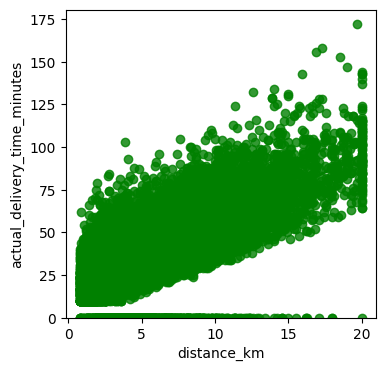

In [ ]:
# Visualizing the correlation by regplot
plt.figure(figsize=(4,4))
sns.regplot(data= dv1, x='distance_km', y= 'actual_delivery_time_minutes', color='green')
plt.ylim(0,)

In [ ]:
'''The chart depicted linear positive between 'distnce_km' and 'actual delivery time'''

In [ ]:
# Creating bin and label for customer_age
bin = np.linspace(dv1['customer_age'].min(),dv1['customer_age'].max(),4)
bin

array([18.        , 30.33333333, 42.66666667, 55.        ])

In [ ]:
bin1 = [np.linspace(min(dv1['customer_age']),max(dv1['customer_age']),4)]
bin1

[array([18.        , 30.33333333, 42.66666667, 55.        ])]

In [ ]:
# Creating variable to generate age_group
bin2 = [17,30,40,50,60]

In [ ]:
# Creating group as a label for bin variable
label =['18 - 29 years', '30 - 40 years', '41 - 50 years', '51 - 60 years']
label

['18 - 29 years', '30 - 40 years', '41 - 50 years', '51 - 60 years']

In [ ]:
# Creating column age_group
dv1['age_group'] = pd.cut(dv1['customer_age'],
                          bins = bin2,
                          labels=label)

In [ ]:
dv1[['customer_age','age_group']].head(10)


,customer_age,age_group
0,40,30 - 40 years
1,19,18 - 29 years
2,26,18 - 29 years
3,18,18 - 29 years
4,20,18 - 29 years
5,45,41 - 50 years
6,25,18 - 29 years
7,25,18 - 29 years
8,28,18 - 29 years
9,28,18 - 29 years


In [ ]:
# Identifying the null rows of age_group column
na_age_group = dv1[dv1['age_group'].isna()][['customer_age','age_group']]
na_age_group

,customer_age,age_group


In [ ]:
dv1['age_group'].isna().sum()
# No is-null rows found in age_group

np.int64(0)

In [ ]:
  # Creating group for order_hour
  hour = [np.linspace(min(dv1['order_hour']),max(dv1['order_hour']),5)]
  hour

[array([ 0.  ,  5.75, 11.5 , 17.25, 23.  ])]

In [ ]:
day = [-1,6,12,18,23]

In [ ]:
label_hour = ['00-06 a.m', '07-12 a.m', '13-18 p.m', '19-23 p.m']
label_hour

['00-06 a.m', '07-12 a.m', '13-18 p.m', '19-23 p.m']

In [ ]:
dv1['hour_group'] = pd.cut(dv1['order_hour'],
                           bins = day,
                           labels = label_hour)

In [ ]:
# Generating columns : order_hour & hour_group
dv1[['order_hour','hour_group']]

,order_hour,hour_group
0,15,13-18 p.m
1,20,19-23 p.m
2,18,13-18 p.m
3,16,13-18 p.m
4,18,13-18 p.m
...,...,...
49995,12,07-12 a.m
49996,19,19-23 p.m
49997,12,07-12 a.m
49998,17,13-18 p.m


In [ ]:
# Identifying hour_group column, should it have is-na rows.
dv1['hour_group'].isnull().sum()

np.int64(0)

In [ ]:
id = dv1[dv1['order_hour'] == 0][['order_hour','hour_group']]
id

,order_hour,hour_group
131,0,00-06 a.m
191,0,00-06 a.m
430,0,00-06 a.m
501,0,00-06 a.m
584,0,00-06 a.m
...,...,...
49087,0,00-06 a.m
49207,0,00-06 a.m
49683,0,00-06 a.m
49759,0,00-06 a.m


In [ ]:
dv1.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 50000 entries, 0 to 49999
Data columns (total 39 columns):
 #   Column                               Non-Null Count  Dtype         
---  ------                               --------------  -----         
 0   order_id                             50000 non-null  object        
 1   customer_id                          50000 non-null  object        
 2   restaurant_id                        50000 non-null  object        
 3   driver_id                            50000 non-null  object        
 4   order_date                           50000 non-null  datetime64[ns]
 5   order_hour                           50000 non-null  int64         
 6   day_of_week                          50000 non-null  object        
 7   is_weekend                           50000 non-null  int64         
 8   city                                 50000 non-null  object        
 9   delivery_area                        50000 non-null  object        
 10  customer_a

In [ ]:
# Identifying what factors drive late deliveries
# Creating variable for temporary DataFrame to apply with Groupby
late = dv1[['late_delivery', 'restaurant_primary_category','actual_delivery_time_minutes']]
grouped_late = np.round(late.groupby(['late_delivery','restaurant_primary_category'],as_index=False).mean(),1)
grouped_late

,late_delivery,restaurant_primary_category,actual_delivery_time_minutes
0,0.0,Asian,32.7
1,0.0,Burger,30.1
2,0.0,Dessert,31.4
3,0.0,Healthy,33.6
4,0.0,Local,30.8
5,0.0,Pizza,31.8
6,1.0,Asian,43.3
7,1.0,Burger,40.9
8,1.0,Dessert,42.5
9,1.0,Healthy,44.3


In [ ]:
# Mapping the group into pivot to get easily interpreted
late_pivot = grouped_late.pivot(index='late_delivery',columns = 'restaurant_primary_category')
late_pivot

actual_delivery_time_minutes                 \
restaurant_primary_category                        Asian Burger Dessert   
late_delivery                                                             
0.0                                                 32.7   30.1    31.4   
1.0                                                 43.3   40.9    42.5   
Cancelled order                                      0.0    0.0     0.0   

                                                 
restaurant_primary_category Healthy Local Pizza  
late_delivery                                    
0.0                            33.6  30.8  31.8  
1.0                            44.3  42.0  43.1  
Cancelled order                 0.0   0.0   0.0

In [ ]:
''' The healthy, Asian and pizza restaurant had the highest rate delay
for actual delivery time at 44.3,43.3, and 43,1 respectively,
contrast with burger that had the shortest time frame in on-time delivery.'''

In [ ]:
# Creating function to identify late delivery in city, hour_group,traffic, weather
def late1 (a,b,c,d):
  late_gr = a[[b,c,d]]
  grby_late = np.round(late_gr.groupby([b,c],as_index=False).mean(),1)
  # Creating pivot
  pivot_grby_late = grby_late.pivot(index= b, columns =c)

  print(f'The Groupby column {b} & {c} from {d} on average : \n {grby_late}')
  print()
  print()
  print(f'The pivot table column {c} with {b} as index: \n {pivot_grby_late}')

In [ ]:
late1(dv1,'late_delivery','city','actual_delivery_time_minutes')

The Groupby column late_delivery & city from actual_delivery_time_minutes on average : 
       late_delivery    city  actual_delivery_time_minutes
0               0.0  City_A                          30.7
1               0.0  City_B                          31.8
2               0.0  City_C                          30.7
3               0.0  City_D                          31.8
4               1.0  City_A                          42.0
5               1.0  City_B                          42.9
6               1.0  City_C                          40.8
7               1.0  City_D                          42.3
8   Cancelled order  City_A                           0.0
9   Cancelled order  City_B                           0.0
10  Cancelled order  City_C                           0.0
11  Cancelled order  City_D                           0.0


The pivot table column city with late_delivery as index: 
                 actual_delivery_time_minutes                     
city                          

In [ ]:
late1(dv1,'late_delivery','weather','actual_delivery_time_minutes')

The Groupby column late_delivery & weather from actual_delivery_time_minutes on average : 
       late_delivery weather  actual_delivery_time_minutes
0               0.0   Clear                          31.8
1               0.0  Cloudy                          30.7
2               0.0    Rain                          27.1
3               0.0   Storm                          24.8
4               1.0   Clear                          39.0
5               1.0  Cloudy                          42.1
6               1.0    Rain                          44.5
7               1.0   Storm                          49.8
8   Cancelled order   Clear                           0.0
9   Cancelled order  Cloudy                           0.0
10  Cancelled order    Rain                           0.0
11  Cancelled order   Storm                           0.0


The pivot table column weather with late_delivery as index: 
                 actual_delivery_time_minutes                   
weather                   

In [ ]:
late1(dv1,'late_delivery','traffic_level','actual_delivery_time_minutes')

The Groupby column late_delivery & traffic_level from actual_delivery_time_minutes on average : 
      late_delivery traffic_level  actual_delivery_time_minutes
0              0.0          High                          35.3
1              0.0           Low                          27.2
2              0.0        Medium                          31.1
3              1.0          High                          47.2
4              1.0           Low                          36.9
5              1.0        Medium                          41.8
6  Cancelled order          High                           0.0
7  Cancelled order           Low                           0.0
8  Cancelled order        Medium                           0.0


The pivot table column traffic_level with late_delivery as index: 
                 actual_delivery_time_minutes             
traffic_level                           High   Low Medium
late_delivery                                            
0.0                         

In [ ]:
# Transforming the datatype hour_group column into string
dv1['hour_group'] = dv1['hour_group'].astype(str)

In [ ]:
late1(dv1,'late_delivery','hour_group','actual_delivery_time_minutes')

The Groupby column late_delivery & hour_group from actual_delivery_time_minutes on average : 
       late_delivery hour_group  actual_delivery_time_minutes
0               0.0  00-06 a.m                          28.2
1               0.0  07-12 a.m                          30.7
2               0.0  13-18 p.m                          31.2
3               0.0  19-23 p.m                          32.3
4               1.0  00-06 a.m                          38.2
5               1.0  07-12 a.m                          41.4
6               1.0  13-18 p.m                          42.1
7               1.0  19-23 p.m                          43.6
8   Cancelled order  00-06 a.m                           0.0
9   Cancelled order  07-12 a.m                           0.0
10  Cancelled order  13-18 p.m                           0.0
11  Cancelled order  19-23 p.m                           0.0


The pivot table column hour_group with late_delivery as index: 
                 actual_delivery_time_minutes 

In [ ]:
''' The Storm and high traffic level had the highest rate for delay of actual delivery
     at 49.8 and 47.2 respectively, recorded city B where the arrival deliveries used to happen,
     meanwhile night-delivery at 19-23 p.m  was the most prolonged period on average  '''

In [ ]:
# identifying the number of late deliveries based on hour_group
np.round(pd.crosstab(dv1['restaurant_primary_category'],dv1['late_delivery'],normalize = 'index')*100,1)

late_delivery,0.0,1.0,Cancelled order
restaurant_primary_category,,,
Asian,61.8,36.7,1.4
Burger,63.1,35.1,1.7
Dessert,62.0,36.2,1.8
Healthy,64.9,33.8,1.3
Local,61.2,36.8,2.0
Pizza,61.4,36.9,1.7


In [ ]:
# Identifying the frequency late deliveries across the time group
np.round(pd.crosstab(dv1['hour_group'],dv1['late_delivery'], normalize ='index')*100,1)

late_delivery,0.0,1.0,Cancelled order
hour_group,,,
00-06 a.m,64.1,34.5,1.4
07-12 a.m,62.6,35.6,1.7
13-18 p.m,61.8,36.5,1.7
19-23 p.m,62.2,35.9,1.9


In [ ]:
''' The frequency of late deliveries across restaurants and hour_group did not
    differ significantly, the pizza retaurant had the highest rate at 36.9%, and
    36.5% in rush hour (07-12 a.m).'''

In [ ]:
# identifying the correlation between partner experienced-months and actual delivery time
partner = dv1[['delivery_partner_experience_months', 'actual_delivery_time_minutes']]
partner.corr()

,delivery_partner_experience_months,actual_delivery_time_minutes
delivery_partner_experience_months,1.000000,-0.001126
actual_delivery_time_minutes,-0.001126,1.000000


In [ ]:
pearson_coef,p_value = stats.pearsonr(dv1['delivery_partner_experience_months'],dv1['actual_delivery_time_minutes'])
print(f'The pearson_coef: {pearson_coef} \n the p_value: {p_value} ')

The pearson_coef: -0.0011263920488654134 
 the p_value: 0.8011471897507926 


In [ ]:
'''Since the p_value > 0.1, the correlation between partner experienced-months
and actual delivery time has no evidence that it's significant, the pearson_coef
measures the two variables most likely do not affect each other.'''


In [ ]:
# print the DataFrame dv1
dv1.to_excel('rest_del.xlsx', index=False)